only increase the model capacity:

Window = 10
LSTM = 16
Dense = 8

This lets us evaluate whether doubling the neurons improves prediction accuracy without changing the temporal history.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

load data

In [6]:
df = pd.read_csv("ds18b20_data.csv")

temps = df["temperature_C"].values.reshape(-1, 1)

print(df.head())
print("Total readings:", len(df))

   timestamp  temperature_C
0     1630.0         26.625
1     4138.0         26.687
2     6646.0         26.750
3     9154.0         26.750
4    11662.0         26.750
Total readings: 2872


normalize

In [7]:
scaler = MinMaxScaler()
temps_scaled = scaler.fit_transform(temps)

print("Scaler min:", scaler.data_min_[0])
print("Scaler max:", scaler.data_max_[0])

Scaler min: 7.312
Scaler max: 38.938


target and independent | create seq

In [8]:
WINDOW = 10

X = []
y = []

for i in range(len(temps_scaled) - WINDOW):
    X.append(temps_scaled[i:i + WINDOW])
    y.append(temps_scaled[i + WINDOW])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2862, 10, 1)
y shape: (2862, 1)


train-test split

In [9]:
split = int(0.8 * len(X))

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("Train samples:", len(X_train))
print("Test samples:", len(X_test))

Train samples: 2289
Test samples: 573


model- 10-16-8

In [10]:
model = Sequential([
    Input(shape=(WINDOW, 1)),
    LSTM(16),
    Dense(8, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()
print("Total Parameters:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,297 (5.07 KB)

 Trainable params: 1,297 (5.07 KB)

 Non-trainable params: 0 (0.00 B)

Total Parameters: 1297


train

In [11]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=25,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0412 - mae: 0.1208 - val_loss: 2.4651e-06 - val_mae: 0.0014
Epoch 2/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 6.7699e-04 - mae: 0.0119 - val_loss: 9.0889e-05 - val_mae: 0.0095
Epoch 3/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 5.7971e-04 - mae: 0.0101 - val_loss: 2.0009e-04 - val_mae: 0.0141
Epoch 4/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 5.6588e-04 - mae: 0.0097 - val_loss: 4.7910e-05 - val_mae: 0.0069
Epoch 5/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 5.5026e-04 - mae: 0.0091 - val_loss: 5.3023e-05 - val_mae: 0.0072
Epoch 6/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 5.4712e-04 - mae: 0.0095 - val_loss: 2.1395e-04 - val_mae: 0.0146
Epoch 7/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 5.2222e-04 - mae: 0.0089 - val_loss: 1.5677e-04 - val_mae: 0.0125
Epoch 8/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 5.1502e-04 - mae: 0.0092 - val_loss: 5.8934e-05 - 

predict

In [12]:
y_pred_scaled = model.predict(X_test)

y_test_actual = scaler.inverse_transform(y_test)
y_pred_actual = scaler.inverse_transform(y_pred_scaled)

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step


In [13]:
mae = mean_absolute_error(y_test_actual, y_pred_actual)
mse = mean_squared_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_test_actual, y_pred_actual) * 100
r2 = r2_score(y_test_actual, y_pred_actual)

print(f"MAE : {mae:.6f} °C")
print(f"MSE : {mse:.6f}")
print(f"RMSE: {rmse:.6f} °C")
print(f"MAPE: {mape:.4f} %")
print(f"R²  : {r2:.6f}")

MAE : 0.027006 °C
MSE : 0.001295
RMSE: 0.035982 °C
MAPE: 0.1150 %
R²  : 0.986028


graphs baby

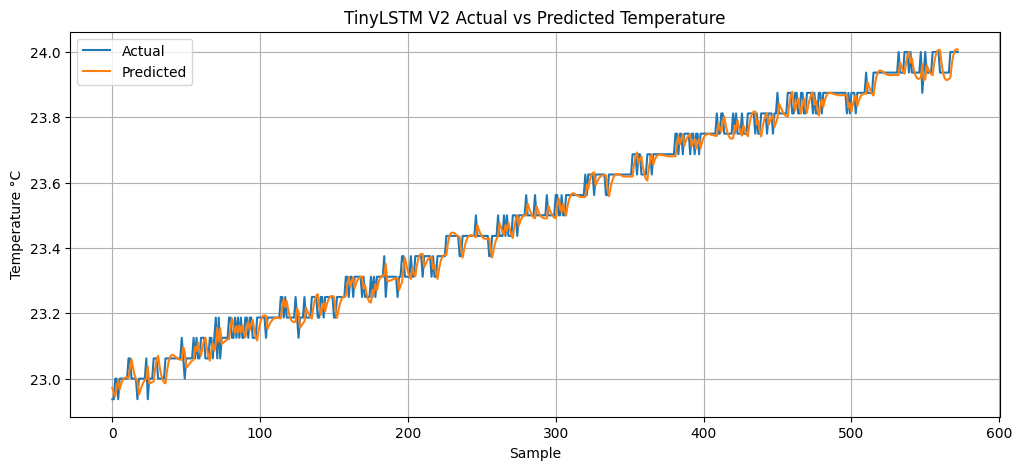

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(y_test_actual, label="Actual")
plt.plot(y_pred_actual, label="Predicted")

plt.title("TinyLSTM V2 Actual vs Predicted Temperature")
plt.xlabel("Sample")
plt.ylabel("Temperature °C")
plt.legend()
plt.grid(True)

plt.show()

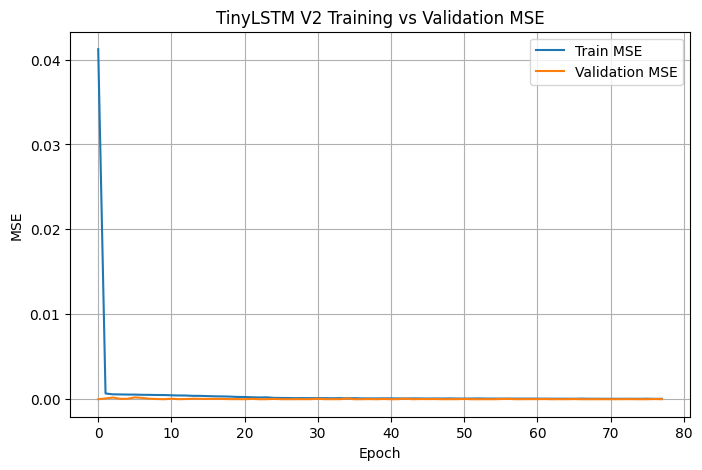

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Train MSE")
plt.plot(history.history["val_loss"], label="Validation MSE")

plt.title("TinyLSTM V2 Training vs Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid(True)

plt.show()

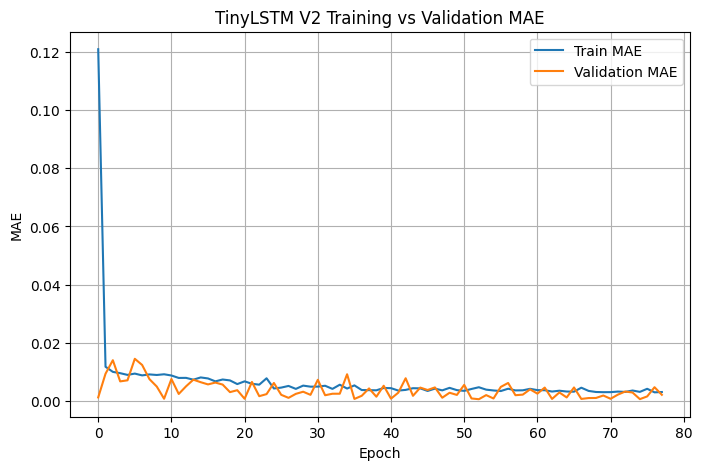

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["mae"], label="Train MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")

plt.title("TinyLSTM V2 Training vs Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()
plt.grid(True)

plt.show()

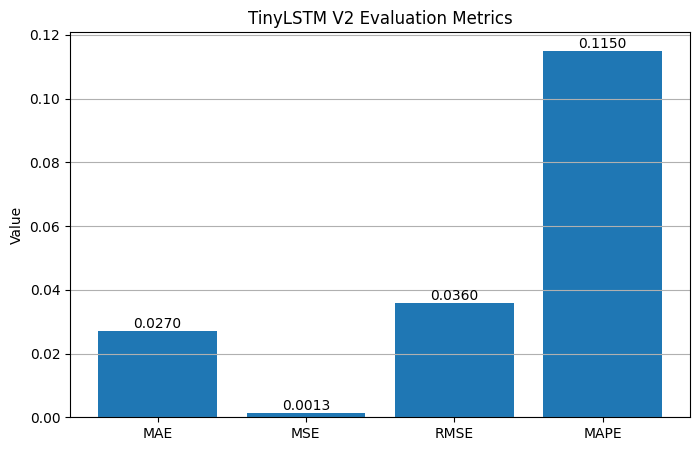

In [17]:
metric_names = ["MAE", "MSE", "RMSE", "MAPE"]
metric_values = [mae, mse, rmse, mape]

plt.figure(figsize=(8, 5))
plt.bar(metric_names, metric_values)

plt.title("TinyLSTM V2 Evaluation Metrics")
plt.ylabel("Value")
plt.grid(axis="y")

for i, v in enumerate(metric_values):
    plt.text(i, v, f"{v:.4f}", ha="center", va="bottom")

plt.show()

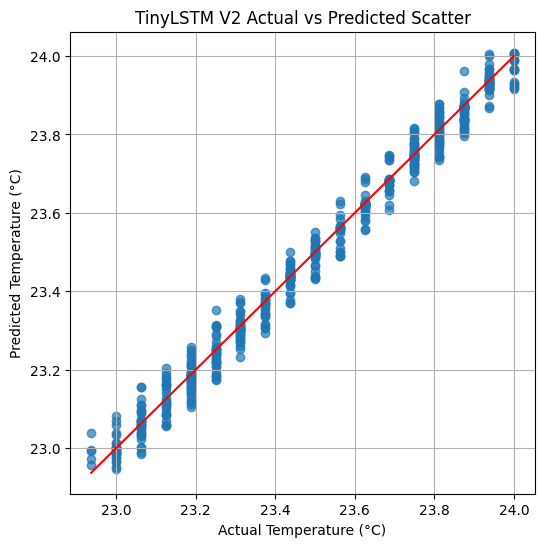

In [18]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test_actual,
    y_pred_actual,
    alpha=0.7
)

plt.plot(
    [y_test_actual.min(), y_test_actual.max()],
    [y_test_actual.min(), y_test_actual.max()],
    "r"
)

plt.title("TinyLSTM V2 Actual vs Predicted Scatter")
plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Predicted Temperature (°C)")
plt.grid(True)

plt.show()

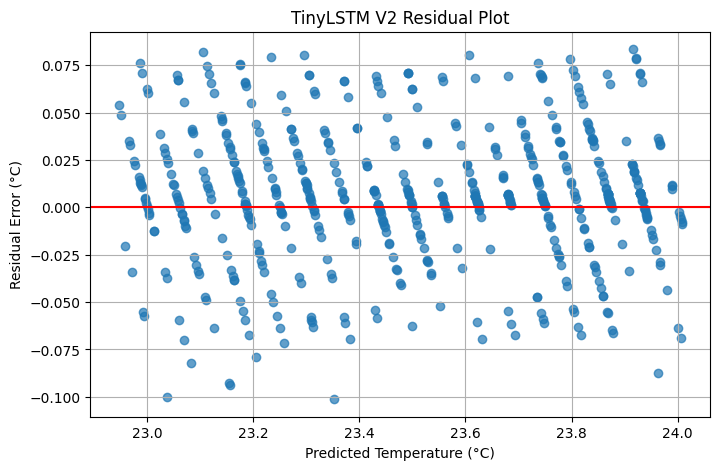

In [19]:
residuals = y_test_actual.flatten() - y_pred_actual.flatten()

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_actual,
    residuals,
    alpha=0.7
)

plt.axhline(0, color="red")

plt.title("TinyLSTM V2 Residual Plot")
plt.xlabel("Predicted Temperature (°C)")
plt.ylabel("Residual Error (°C)")
plt.grid(True)

plt.show()

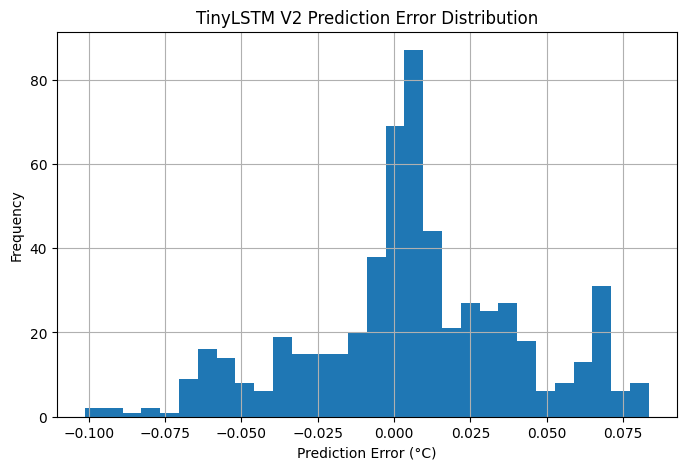

In [20]:
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=30)

plt.title("TinyLSTM V2 Prediction Error Distribution")
plt.xlabel("Prediction Error (°C)")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

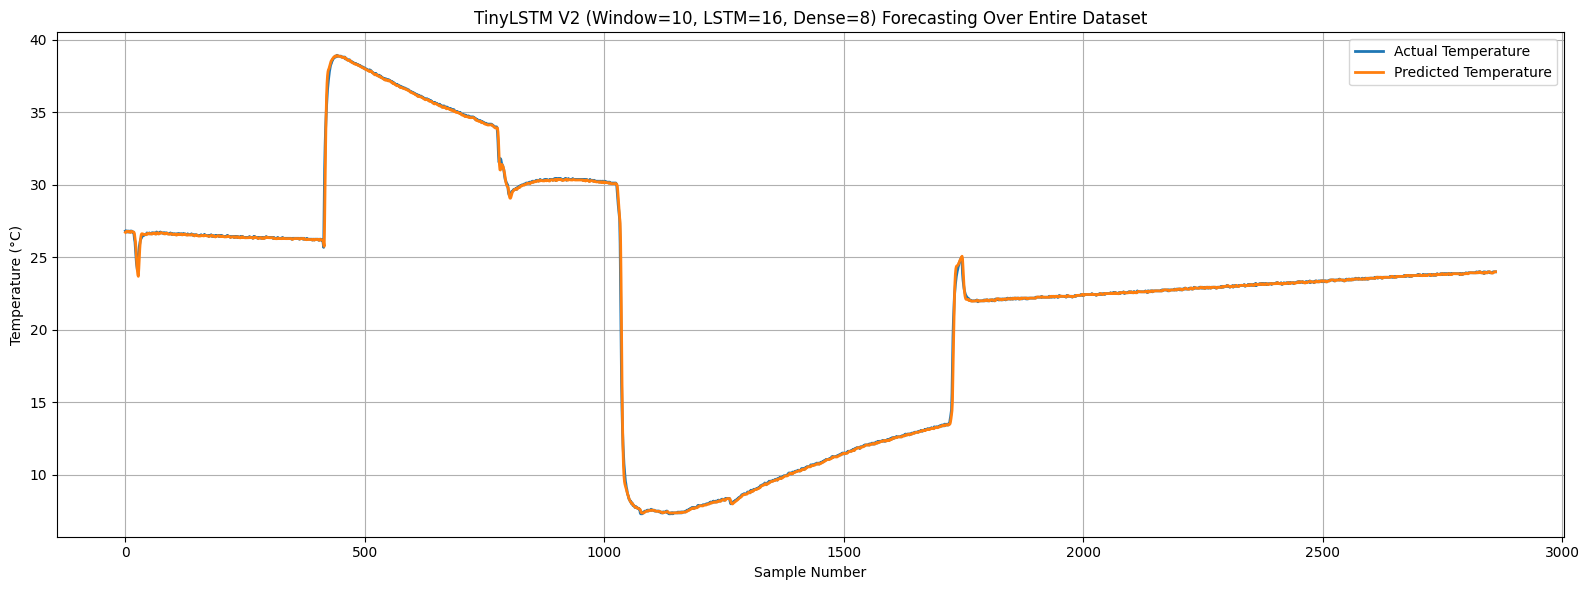

In [24]:
y_all_pred_scaled = model.predict(X, verbose=0)

y_all_actual = scaler.inverse_transform(y)
y_all_pred = scaler.inverse_transform(y_all_pred_scaled)

plt.figure(figsize=(16,6))

plt.plot(
    y_all_actual,
    label="Actual Temperature",
    linewidth=2
)

plt.plot(
    y_all_pred,
    label="Predicted Temperature",
    linewidth=2
)

plt.title("TinyLSTM V2 (Window=10, LSTM=16, Dense=8) Forecasting Over Entire Dataset")
plt.xlabel("Sample Number")
plt.ylabel("Temperature (°C)")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

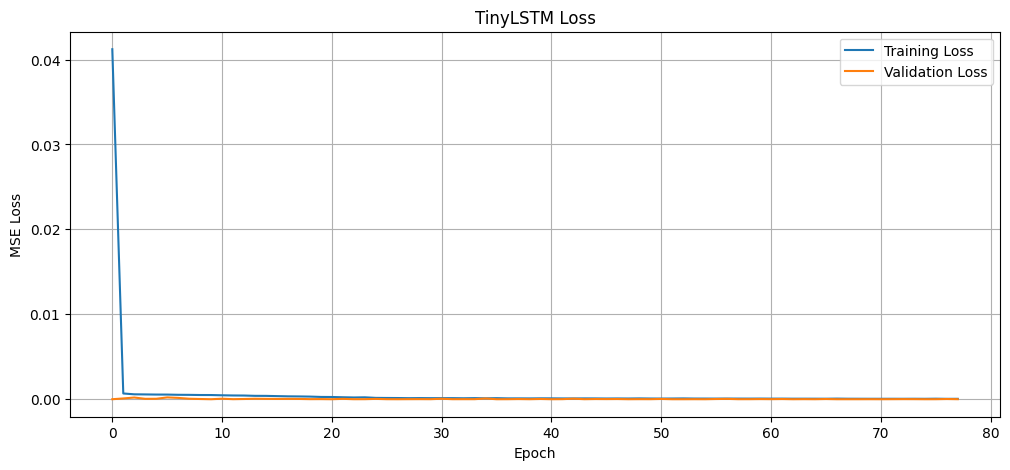

In [23]:
plt.figure(figsize=(12,5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("TinyLSTM Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()

plt.grid(True)

plt.show()

In [25]:
lstm_w, lstm_u, lstm_b = model.layers[0].get_weights()
dense1_w, dense1_b = model.layers[1].get_weights()
dense2_w, dense2_b = model.layers[2].get_weights()

def array_to_cpp(name, arr):
    flat = arr.flatten()
    text = f"const float {name}[] = {{\n"

    for i, value in enumerate(flat):
        text += f"{value:.9f}f, "
        if (i + 1) % 8 == 0:
            text += "\n"

    text += "\n};\n\n"
    return text

cpp = ""
cpp += "// TinyLSTM V2: Window=10, LSTM=16, Dense=8\n\n"

cpp += array_to_cpp("lstm_kernel_flat", lstm_w)
cpp += array_to_cpp("lstm_recurrent_kernel_flat", lstm_u)
cpp += array_to_cpp("lstm_bias", lstm_b)

cpp += array_to_cpp("dense1_weights_flat", dense1_w)
cpp += array_to_cpp("dense1_bias", dense1_b)

cpp += array_to_cpp("dense2_weights_flat", dense2_w)
cpp += array_to_cpp("dense2_bias", dense2_b)

with open("tinylstm_v2_arrays.txt", "w") as f:
    f.write(cpp)

print("Saved tinylstm_v2_arrays.txt")

print("LSTM kernel:", lstm_w.shape)
print("LSTM recurrent kernel:", lstm_u.shape)
print("LSTM bias:", lstm_b.shape)

print("Dense1 weights:", dense1_w.shape)
print("Dense1 bias:", dense1_b.shape)

print("Dense2 weights:", dense2_w.shape)
print("Dense2 bias:", dense2_b.shape)

Saved tinylstm_v2_arrays.txt
LSTM kernel: (1, 64)
LSTM recurrent kernel: (16, 64)
LSTM bias: (64,)
Dense1 weights: (16, 8)
Dense1 bias: (8,)
Dense2 weights: (8, 1)
Dense2 bias: (1,)
